# 3. Optimización computacional

Objetivo (Sección 4 de la guía): reducir el costo manteniendo el desempeño, contrastando la complejidad
teórica O(·) con tiempos medidos. Todas las mediciones usan el escenario A, el conjunto de desarrollo
preprocesado (p = 173 columnas tras One-Hot) y la mediana de 3 repeticiones para reducir la varianza.

Entorno de ejecución de este informe: 2 núcleos de CPU, sin GPU (el código de GPU se documenta en 3.5).

In [1]:
import sys, os, warnings, json, platform
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config as C
from src.data import load_model_data, split_dev_test, xyg
from src.models import MODELS, MODEL_ORDER
from src.computational import (scaling_experiment, scaling_exponents, standard_vs_optimized,
                               successive_halving_vs_random, parallel_speedup, profile_search)
from src.viz import set_style, MODEL_COLORS, SERIES, INK2, MUTED

C.set_global_seed()
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
print(f"Python {platform.python_version()} | CPU: {os.cpu_count()} núcleos | plataforma: {platform.machine()}")

df = load_model_data()
dev, test = split_dev_test(df)
X, y, g = xyg(dev)
Xt, yt, _ = xyg(test)
mt = pd.read_csv(C.RESULTS_DIR / "master_table.csv")
mtA = mt[mt.scenario == "A_estructural"]
# hiperparámetros finales del mejor optimizador de cada modelo
best_row = mtA.loc[mtA.groupby("model")["outer_rmse_mean"].idxmin()].set_index("model")
best_params = {m: json.loads(best_row.loc[m, "final_params"]) for m in MODEL_ORDER}
best_row[["method", "outer_rmse_mean"]]

Python 3.13.16 | CPU: 2 núcleos | plataforma: x86_64


,method,outer_rmse_mean
model,,
DecisionTree,Genetica,2.4475
KNN,Bayesiana,2.6127
Lasso,Bayesiana,2.7047
RandomForest,Random,2.0082
Ridge,Random,2.6832
SVR,Bayesiana,2.1867
XGBoost,Grid,2.0573


## 3.1 Complejidad teórica de los modelos optimizados

In [2]:
pd.DataFrame([{"modelo": m, "entrenamiento": MODELS[m].complexity_train, "inferencia": MODELS[m].complexity_predict}
              for m in MODEL_ORDER])

,modelo,entrenamiento,inferencia
0,KNN,O(1) (fuerza bruta) | O(n·p·log n) (KD/Ball tree),O(n·p) por consulta (fuerza bruta) | ~O(p·log ...
1,Ridge,O(n·p² + p³) (Cholesky) | O(n·p) por iteración...,O(p)
2,Lasso,O(n·p) por iteración (descenso coordenado) | O...,O(p)
3,DecisionTree,O(n·p·log n),O(profundidad) ≈ O(log n)
4,RandomForest,"O(T·n·m·log n), m = max_features·p",O(T·log n)
5,XGBoost,O(T·(n·p) ) con 'hist' (O(T·n·p·log n) con 'ex...,O(T·profundidad)
6,SVR,"O(n²·p) a O(n³) (kernel RBF, libsvm)",O(n_SV·p)


## 3.2 Escalamiento empírico con n

Se mide el tiempo de ajuste y de predicción (500 consultas fijas) variando n con p fijo. La pendiente de
log(tiempo) frente a log(n) estima el exponente empírico *b* en t ∝ n^b, que se contrasta con la teoría.

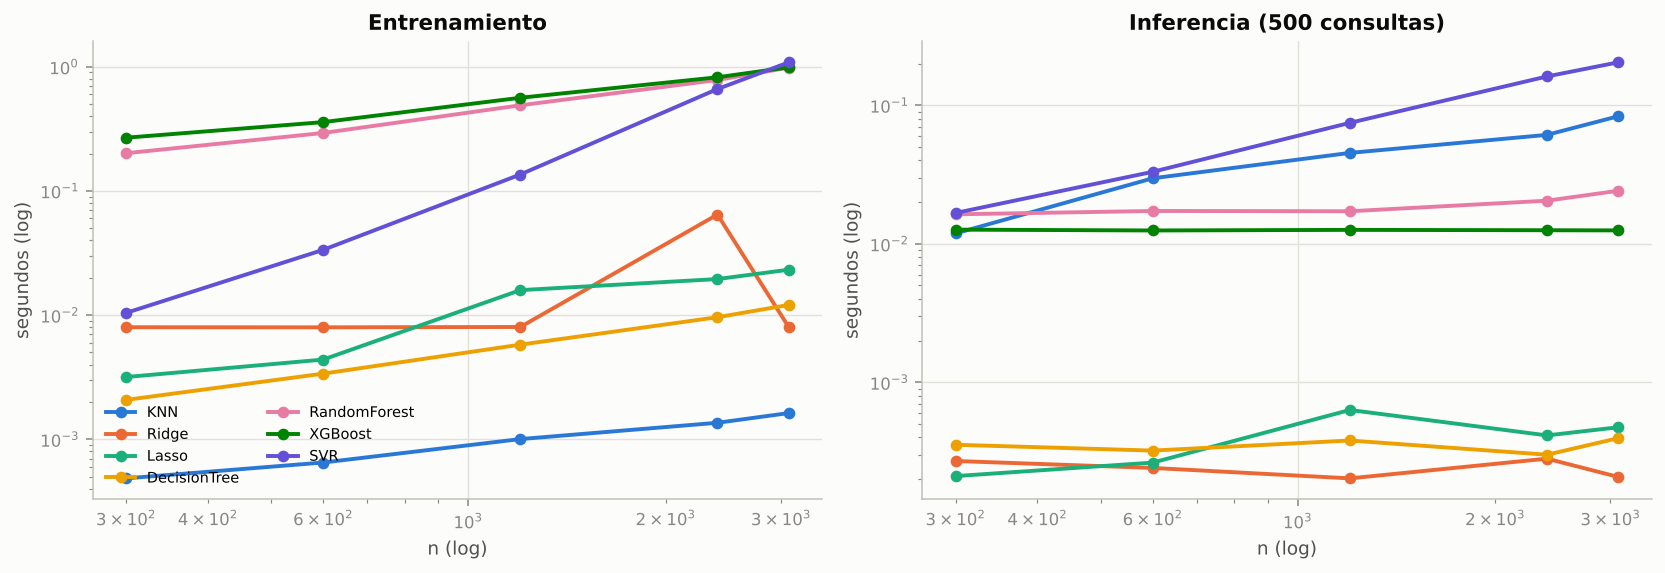

,exp_fit,exp_predict,teoría entrenamiento,teoría inferencia
model,,,,
KNN,0.5202,0.7653,≈0 (solo almacena),≈1 (fuerza bruta: O(n·p))
Ridge,0.4369,-0.0535,"≈1 (O(n·p²), p fijo)",0
Lasso,0.9163,0.3559,≈1 por iteración,0
DecisionTree,0.7530,0.0133,≈1–1.1 (n log n),≈0 (log n)
RandomForest,0.6832,0.1480,≈1–1.1 (n log n),≈0 (log n)
XGBoost,0.5661,-0.0035,≈1 (hist),≈0
SVR,2.0248,1.0925,≈2 (O(n²) a O(n³)),≈1 (n_SV ∝ n)


In [3]:
cache = C.RESULTS_DIR / "scaling.csv"
if cache.exists():
    sc = pd.read_csv(cache)
else:
    sc = scaling_experiment(X, y, best_params, sizes=(300, 600, 1200, 2400, 3085))
    sc.to_csv(cache, index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for m in MODEL_ORDER:
    s = sc[sc.model == m]
    axes[0].plot(s.n, s.fit_s, marker="o", color=MODEL_COLORS[m], label=m)
    axes[1].plot(s.n, s.predict_s, marker="o", color=MODEL_COLORS[m], label=m)
for ax, t in zip(axes, ["Entrenamiento", "Inferencia (500 consultas)"]):
    ax.set(xscale="log", yscale="log", xlabel="n (log)", ylabel="segundos (log)", title=t)
axes[0].legend(ncol=2, fontsize=7.5)
plt.tight_layout()

theory = {"KNN": ("≈0 (solo almacena)", "≈1 (fuerza bruta: O(n·p))"), "Ridge": ("≈1 (O(n·p²), p fijo)", "0"),
          "Lasso": ("≈1 por iteración", "0"), "DecisionTree": ("≈1–1.1 (n log n)", "≈0 (log n)"),
          "RandomForest": ("≈1–1.1 (n log n)", "≈0 (log n)"), "XGBoost": ("≈1 (hist)", "≈0"),
          "SVR": ("≈2 (O(n²) a O(n³))", "≈1 (n_SV ∝ n)")}
ex = scaling_exponents(sc).set_index("model").loc[MODEL_ORDER]
ex["teoría entrenamiento"] = [theory[m][0] for m in ex.index]
ex["teoría inferencia"] = [theory[m][1] for m in ex.index]
ex

**Interpretación (teoría vs medición).**

- **SVR-RBF** es el único con comportamiento claramente superlineal: exponente de entrenamiento ≈ 2.0, que
  coincide con el O(n²·p) del cálculo de la matriz kernel en libsvm, e inferencia ≈ 1.1, coherente con
  O(n_SV·p) cuando el número de vectores soporte crece con n. Es el modelo que no escalaría a millones de filas.
- **KNN**: la inferencia por fuerza bruta escala ≈ n^0.77 (teoría: lineal); la diferencia se debe a costos
  fijos por consulta (validación de entrada, ordenamiento parcial de los k vecinos) que pesan más con n pequeño. El
  "entrenamiento" (≈ n^0.5) solo copia datos y es despreciable en valor absoluto (< 1 ms).
- **Árboles, Random Forest y XGBoost**: exponentes de 0.57–0.75, por debajo del n·log n teórico. Con
  n ≤ 3.000 hay costos fijos por árbol (validación de parámetros, creación de nodos, construcción de
  histogramas en XGBoost) que no dependen de n y aplanan la pendiente. La inferencia es casi constante en n
  (exponentes ≈ 0–0.15), como predice O(T·profundidad).
- **Ridge** (≈ 0.44) y **Lasso** (≈ 0.92): con p = 173 fijo, Cholesky resuelve un sistema p × p cuyo costo
  O(p³) no depende de n; solo la formación de XᵀX es lineal en n. Lasso (descenso coordenado) se acerca a la
  linealidad esperada. Su predicción no depende de n (≈ 0), tal como O(p).

En resumen, el orden de complejidad se confirma en los extremos (SVR cuadrático, predicción de modelos
paramétricos constante) y, para tamaños pequeños, los costos fijos hacen que los exponentes empíricos
queden por debajo de los asintóticos.

## 3.3 Modelo estándar vs optimizado

Cada variante se entrena con los mismos datos (desarrollo) y se evalúa en el hold-out. `speedup` > 1
indica que la variante es más rápida que la versión estándar (primera fila de cada modelo);
`delta_rmse` > 0 indica pérdida de precisión. La memoria es el pico de asignaciones de Python
(`tracemalloc`) durante ajuste + predicción.

FAISS (vecinos aproximados) no está disponible en este entorno; el código queda preparado en el
bloque siguiente para ejecutarse donde `faiss-cpu` esté instalado. Como alternativa aproximada se
incluye PCA(20) + KD-Tree, que ilustra el mismo compromiso exactitud–velocidad.

In [4]:
cache = C.RESULTS_DIR / "standard_vs_optimized.csv"
if cache.exists():
    svo = pd.read_csv(cache)
else:
    svo = standard_vs_optimized(X, y, Xt, yt, best_params)
    svo.to_csv(cache, index=False)
svo[["model", "variant", "complexity", "fit_s", "predict_s", "peak_mem_MB", "rmse", "speedup_fit",
     "speedup_predict", "delta_rmse"] + (["n_trees"] if "n_trees" in svo else [])]

,model,variant,complexity,fit_s,predict_s,peak_mem_MB,rmse,speedup_fit,speedup_predict,delta_rmse,n_trees
0,KNN,Estándar: fuerza bruta,O(1) / O(n·p) por consulta,0.0006,0.1189,0.8854,2.1292,1.0000,1.0000,0.0000,NaN
1,KNN,KD-Tree,O(n·p·log n) / ~O(p·log n) en baja dim.,0.0382,0.2141,1.2743,2.1300,0.0150,0.5554,0.0008,NaN
2,KNN,Ball-Tree,O(n·p·log n) / ~O(p·log n),0.0168,0.2400,1.0982,2.1298,0.0342,0.4954,0.0006,NaN
3,KNN,Aproximado: PCA(20) + KD-Tree,O(n·p·d) + O(n·d·log n) / ~O(d·log n),0.0098,0.0301,1.6089,2.4215,0.0585,3.9500,0.2923,NaN
4,Ridge,Estándar: Cholesky,O(n·p² + p³),0.0080,0.0002,4.5712,2.6703,1.0000,1.0000,0.0000,NaN
5,Ridge,SAGA,O(n·p) por época,0.0607,0.0002,4.4138,2.6703,0.1310,0.9726,0.0000,NaN
6,Lasso,Estándar: descenso coordenado,O(n·p) por iteración,0.0206,0.0002,4.3485,2.6402,1.0000,1.0000,0.0000,NaN
7,Lasso,SGD (penalización L1),"O(n·p) por época, online",0.3921,0.0002,0.0785,2.5805,0.0526,1.0170,-0.0597,NaN
8,XGBoost,"Estándar: tree_method='exact', 600 árboles",O(T·n·p·log n),8.1271,0.0234,4.2169,1.7029,1.0000,1.0000,0.0000,NaN
9,XGBoost,"tree_method='hist', 600 árboles",O(T·n·p) (histogramas),0.9137,0.0178,4.0870,1.6481,8.8948,1.3183,-0.0548,NaN


In [5]:
try:  # FAISS: búsqueda aproximada de vecinos (IVF). Se ejecuta solo si faiss-cpu está instalado.
    import faiss
    from src.data import make_preprocessor
    import time
    prep = make_preprocessor().fit(X)
    Ztr = np.ascontiguousarray(prep.transform(X), dtype="float32")
    Zte = np.ascontiguousarray(prep.transform(Xt), dtype="float32")
    k = int(best_params["KNN"]["n_neighbors"])
    quant = faiss.IndexFlatL2(Ztr.shape[1])
    index = faiss.IndexIVFFlat(quant, Ztr.shape[1], 32)
    t0 = time.perf_counter(); index.train(Ztr); index.add(Ztr); t_fit = time.perf_counter() - t0
    index.nprobe = 4
    t0 = time.perf_counter(); D, I = index.search(Zte, k); t_pred = time.perf_counter() - t0
    pred = y[I].mean(1)
    print(f"FAISS IVF: fit {t_fit:.4f}s, predict {t_pred:.4f}s, RMSE {np.sqrt(np.mean((yt - pred) ** 2)):.3f}")
except ImportError:
    print("faiss no está instalado en este entorno: se omite (pip install faiss-cpu para ejecutarlo).")

faiss no está instalado en este entorno: se omite (pip install faiss-cpu para ejecutarlo).


**Interpretación.**

- **KNN:** con 173 dimensiones (One-Hot), KD-Tree y Ball-Tree son **más lentos** que la fuerza bruta (la
  inferencia tarda ~2 veces más): en alta dimensión la poda geométrica deja de funcionar y el árbol termina
  visitando casi todos los puntos (maldición de la dimensionalidad), con el costo adicional de recorrerlo. El
  O(log n) teórico solo aplica en baja dimensión. Reducir primero a 20 componentes (PCA) y luego indexar
  acelera la inferencia ~4 veces, a cambio de +0.29 USD/Bbl de RMSE: es el compromiso exactitud–velocidad de
  los vecinos aproximados (FAISS haría lo mismo con índices IVF/HNSW).
- **Ridge/Lasso:** con p = 173, Cholesky (O(p³) ≈ 5 M operaciones) es más rápido que SAGA; SAGA solo
  conviene cuando n y p son grandes o la matriz es dispersa. SGD con L1 consume 50 veces menos memoria (no
  forma XᵀX), lo que importa en aprendizaje *online*, pero aquí es más lento.
- **XGBoost:** `hist` es **8.4×** más rápido que `exact` con el mismo número de árboles y RMSE incluso menor
  (−0.05), porque discretiza cada variable en ≤ 256 cortes en vez de ordenar todos los valores en cada nodo.
  El *early stopping* depende del *learning rate*: con el lr ajustado (0.01) la pérdida de validación sigue
  bajando hasta 2.000 árboles y no corta (más lento). Con lr = 0.05 se detiene en 467 árboles y es **9.8×**
  más rápido que `exact`, con RMSE prácticamente igual (+0.003).
- **SVR:** las alternativas lineales (LinearSVR, SGD) entrenan 5–74× más rápido y predicen >1.000× más rápido,
  pero pierden 0.55–0.79 de RMSE: el problema es no lineal. Nyström (aproximación de rango 300 del kernel RBF)
  conserva la no linealidad, predice ~58× más rápido y pierde 0.17 de RMSE; es la opción si n creciera
  (el SVR exacto escala ≈ n², sección 3.2).

**Tabla resumen (modelo estándar → mejor variante):** XGBoost `exact` → `hist` (+ ES con lr 0.05):
speedup 8–10×, ΔRMSE ≈ 0; SVR exacto → Nyström: inferencia 58×, ΔRMSE +0.17; KNN fuerza bruta →
PCA + KD-Tree: inferencia 4×, ΔRMSE +0.29; Ridge/Lasso: la versión estándar ya es la óptima para este tamaño.

## 3.4 Optimización multi-fidelidad: Successive Halving

- **Fidelidad:** número de árboles (`n_estimators`). Es la elección natural en ensambles: el costo es
  lineal en el número de árboles y el ranking de configuraciones con pocos árboles está muy
  correlacionado con el ranking con muchos.
- **Factor de reducción η = 3:** cada ronda conserva el tercio superior y triplica su presupuesto:
  27 candidatos con 20 árboles → 9 con 60 → 3 con 180 → 1 con 540. η = 3 es el valor recomendado por
  Li et al. (Hyperband): equilibra agresividad de la poda y riesgo de descartar configuraciones que
  mejoran tarde.
- Se compara con Random Search de los mismos 27 candidatos evaluados siempre con 540 árboles.

In [6]:
cache = C.RESULTS_DIR / "successive_halving.csv"
if cache.exists():
    sh = pd.read_csv(cache)
else:
    sh = pd.concat([successive_halving_vs_random(X, y, g, m) for m in ["XGBoost", "RandomForest"]], ignore_index=True)
    sh.to_csv(cache, index=False)
sh["ahorro de tiempo (%)"] = 100 * (1 - sh["time_s"] / sh.groupby("model")["time_s"].transform("first"))
sh["árboles ajustados (rel.)"] = sh["total_trees_fitted"] / sh.groupby("model")["total_trees_fitted"].transform("first")
sh

,model,method,time_s,n_candidates,best_rmse,total_trees_fitted,rounds,candidates_per_round,resources_per_round,ahorro de tiempo (%),árboles ajustados (rel.)
0,XGBoost,Random (fidelidad completa),26.9493,27,2.3024,43740,NaN,NaN,NaN,0.0000,1.0000
1,XGBoost,Successive Halving (η=3),12.9726,27,2.4649,6480,4.0000,"[27, 9, 3, 1]","[20, 60, 180, 540]",51.8629,0.1481
2,RandomForest,Random (fidelidad completa),137.6344,27,2.2466,43740,NaN,NaN,NaN,0.0000,1.0000
3,RandomForest,Successive Halving (η=3),35.0135,27,2.2526,6480,4.0000,"[27, 9, 3, 1]","[20, 60, 180, 540]",74.5605,0.1481


**Interpretación.**

- **Random Forest:** Successive Halving reduce el tiempo un 75 % (de 138 s a 35 s) y ajusta 6.8 veces
  menos árboles, con el mismo RMSE (2.253 vs 2.247). En RF el error con 20 árboles ya ordena bien las
  configuraciones, porque los árboles son independientes: más árboles solo reducen la varianza.
- **XGBoost:** ahorra el 52 % del tiempo pero **empeora** el resultado (2.46 vs 2.30). En *boosting* la
  fidelidad "pocos árboles" está sesgada: con 20 árboles las configuraciones con *learning rate* alto
  parecen mejores y las de *learning rate* bajo (las que finalmente ganan, ≈ 0.01) se eliminan en la
  primera ronda. La correlación de rangos entre baja y alta fidelidad es baja y la poda es prematura.
- **Lección:** la métrica de fidelidad debe preservar el ranking. Para XGBoost conviene usar como recurso
  el tamaño de la submuestra de filas, o escalar el *learning rate* con el número de árboles (lr·T constante).

## 3.5 Paralelización y cómputo distribuido

- Entre modelos y pliegues: la CV anidada completa (`src/nested_cv.py`) reparte las 308 + 77 tareas
  (escenario × modelo × método × pliegue) con `joblib` (backend `loky`, procesos); dentro de cada tarea
  todo usa `n_jobs=1` para evitar sobresuscripción.
- Abajo se mide el *speedup* de una validación cruzada de Random Forest con `loky` (procesos) y
  `threading` (hilos).

In [7]:
cache = C.RESULTS_DIR / "parallel.csv"
if cache.exists():
    par = pd.read_csv(cache)
else:
    par = parallel_speedup(X, y, g, "RandomForest", best_params["RandomForest"])
    par.to_csv(cache, index=False)
par

,model,backend,n_jobs,time_s,speedup
0,RandomForest,secuencial,1,5.5283,1.0000
1,RandomForest,loky,2,3.3783,1.6364
2,RandomForest,threading,2,3.0916,1.7882


**Interpretación.** Con 2 núcleos, la validación cruzada de 6 pliegues pasa de 5.5 s a 3.4 s con `loky`
(speedup 1.64) y a 3.1 s con `threading` (1.79). El speedup ideal sería 2; la diferencia se debe a la
creación de procesos y la serialización de datos en `loky`, y a las partes de Python que no liberan el GIL
en `threading`. `threading` gana aquí porque el ajuste de árboles en scikit-learn ocurre en código Cython que
libera el GIL, sin costo de copiar datos entre procesos. En la CV anidada completa se usó `loky` entre tareas
porque Optuna y DEAP ejecutan mucho Python puro (que con hilos competiría por el GIL).

**Dask / Ray.** Con 385 tareas de duración entre 2 s y 2 min y datos de ~3.000 filas, el cuello de botella
es el número de núcleos, no la memoria ni el tamaño de los datos: `joblib` en una sola máquina es
suficiente. Si se escalara a otra máquina o clúster bastaría con cambiar el backend sin tocar el código:

```python
from dask.distributed import Client
client = Client("tcp://scheduler:8786")
with joblib.parallel_backend("dask"):
    run_experiment(dev, test, "A_estructural")
```

**GPU.** No hay GPU en este entorno. Con una GPU NVIDIA, XGBoost se acelera cambiando un parámetro
(`XGBRegressor(tree_method="hist", device="cuda")`); con ~3.000 filas la ganancia esperada es pequeña o
nula porque la transferencia de datos y el lanzamiento de kernels dominan el costo. El factor de
aceleración se mediría con el mismo `measure()` de `src/computational.py`.

## 3.6 Perfilamiento (cProfile + tracemalloc)

Se perfila una búsqueda Bayesiana de Random Forest (5 evaluaciones) para identificar dónde se gasta el
tiempo antes de optimizar.

In [8]:
cache = C.RESULTS_DIR / "profile.csv"
if cache.exists():
    prof = pd.read_csv(cache)
    peak = float(open(C.RESULTS_DIR / "profile_peak.txt").read())
else:
    prof, peak = profile_search(X, y, g, "RandomForest", "Bayesiana", budget=5, top=12)
    prof.to_csv(cache, index=False)
    open(C.RESULTS_DIR / "profile_peak.txt", "w").write(str(peak))
print(f"Memoria pico de Python durante la búsqueda: {peak:.1f} MB")
prof

Memoria pico de Python durante la búsqueda: 6.5 MB


,function,ncalls,tottime_s,cumtime_s
0,inner (_ufunc_config.py:496),5921,7.8511,7.9169
1,_fit (_classes.py:226),2937,7.1123,16.5109
2,check_random_state (validation.py:1455),8826,5.0395,13.1040
3,_signature_from_function (inspect.py:2403),15706,4.1266,9.7890
4,<method 'get' of 'dict' objects> (~:0),579708,1.5243,1.5243
5,__init__ (inspect.py:2775),197757,1.5060,2.6006
6,<built-in method builtins.isinstance> (~:0),1334077,1.1998,1.5422
7,__call__ (parallel.py:140),5979,1.1322,42.4107
8,<method 'append' of 'list' objects> (~:0),280792,0.7504,0.7504
9,__init__ (inspect.py:3063),15706,0.6691,0.7987


**Interpretación.** El perfil muestra que el cuello de botella **no** es solo el algoritmo: entre las
funciones con más tiempo propio están la construcción de árboles (`_fit`, 7.1 s), pero también costos
administrativos de scikit-learn por cada árbol: `_ufunc_config.inner` (contextos de `np.errstate`, 7.9 s),
`check_random_state` (5.0 s) y la inspección de firmas (`inspect.signature`, 4.1 s). Con árboles pequeños sobre
~2.000 filas, esa sobrecarga fija por árbol pesa tanto como el cálculo. Esto explica los exponentes de
escalamiento menores que 1 (3.2) y sugiere dos mejoras: menos árboles más profundos o XGBoost con `hist`, que
construye todos los árboles en C++ sin esa sobrecarga por árbol. La memoria pico (6.5 MB de objetos Python) es
irrelevante para este tamaño de datos.